# Price Response Uncertainty

## 1. Load Required Data and Model Artifacts

### Objective
Load the historical retail data, SKU cluster mapping and final demand model
required for price-response estimation and forecast uncertainty analysis.

### Architecture
The demand model produces the baseline next-week demand forecast.

Historical price-response behaviour is then used to adjust that baseline under
different markdown scenarios.

Prediction uncertainty is estimated separately from historical forecasting errors.

In [18]:
import pandas as pd
import numpy as np
import joblib

# ---------------------------------------------------------
# Load Full Historical Dataset
# ---------------------------------------------------------

raw_path = (
    "../data/raw/"
    "SmartMarkdown_Data_Dev_2024_2025.xlsx"
)

df = pd.read_excel(raw_path)

df["Week_Start"] = pd.to_datetime(df["Week_Start"]
)

# ---------------------------------------------------------
# Load SKU Cluster Mapping
# ---------------------------------------------------------

cluster_path = (
    "../data/processed/"
    "smartmarkdown_sku_cluster_mapping.csv"
)

cluster_mapping = pd.read_csv(cluster_path)

# ---------------------------------------------------------
# Load Final Demand Model
# ---------------------------------------------------------

demand_model = joblib.load(
    "../models/"
    "smartmarkdown_demand_model.joblib"
)

print("Historical Data Shape:", df.shape)
print("Unique SKUs:", df["SKU_ID"].nunique())

print("\nCluster Mapping Shape:",cluster_mapping.shape)

print("\nCluster Distribution:")
display(cluster_mapping["Cluster_Label"].value_counts())

Historical Data Shape: (4200, 30)
Unique SKUs: 40

Cluster Mapping Shape: (40, 3)

Cluster Distribution:


Cluster_Label
High-Demand Fast-Moving            18
Slow-Moving Markdown-Responsive    14
Volatile Low-Response               8
Name: count, dtype: int64

## 2. Historical Price-Response Estimation

### Objective
Estimate how demand historically changes as markdown levels change for each SKU.

### Method
A simple SKU-level linear relationship is estimated between same-week
Discount_Pct and Latent_Demand.

The resulting slope represents the approximate historical demand change
associated with a one-percentage-point change in discount.

This relationship is used as an interpretable scenario adjustment rather than
as a separate demand forecasting model.

### Important Limitation
The estimated relationship represents historical association and should not be
interpreted as a causal price elasticity estimate.

In [19]:
# ---------------------------------------------------------
# SKU-Level Discount Response Slope
# ---------------------------------------------------------

price_response_records = []

for sku_id, group in df.groupby("SKU_ID"):

    x = group["Discount_Pct"].values
    y = group["Latent_Demand"].values

    # Linear slope:
    # approximate demand-unit change per +1 percentage point discount
    slope, intercept = np.polyfit(x,y,1)

    corr = group["Discount_Pct"].corr(group["Latent_Demand"])

    price_response_records.append({
        "SKU_ID": sku_id,
        "Demand_Per_1Pct_Discount": slope,
        "Discount_Demand_Corr": corr
    })

price_response_df = pd.DataFrame(
    price_response_records
)

display(
    price_response_df.head()
)

,SKU_ID,Demand_Per_1Pct_Discount,Discount_Demand_Corr
0,SKU001,0.717576,0.734870
1,SKU002,0.718847,0.626153
2,SKU003,0.691383,0.824142
3,SKU004,0.623267,0.743742
4,SKU005,0.559624,0.770979


In [20]:
price_response_df = price_response_df.merge(
    cluster_mapping[
        [
            "SKU_ID",
            "Cluster",
            "Cluster_Label"
        ]
    ],
    on="SKU_ID",how="left"
)

display(
    price_response_df.head()
)

,SKU_ID,Demand_Per_1Pct_Discount,Discount_Demand_Corr,Cluster,Cluster_Label
0,SKU001,0.717576,0.734870,2,High-Demand Fast-Moving
1,SKU002,0.718847,0.626153,2,High-Demand Fast-Moving
2,SKU003,0.691383,0.824142,2,High-Demand Fast-Moving
3,SKU004,0.623267,0.743742,2,High-Demand Fast-Moving
4,SKU005,0.559624,0.770979,2,High-Demand Fast-Moving


In [21]:
display(
    price_response_df[
        [
            "Demand_Per_1Pct_Discount",
            "Discount_Demand_Corr"
        ]
    ]
    .describe().T
)

,count,mean,std,min,25%,50%,75%,max
Demand_Per_1Pct_Discount,40.0,0.527919,0.188589,0.146542,0.366947,0.525213,0.638777,1.080826
Discount_Demand_Corr,40.0,0.724344,0.104858,0.475975,0.707128,0.749334,0.788862,0.911724


In [22]:
cluster_price_response = (
    price_response_df
    .groupby("Cluster_Label")
    .agg(SKU_Count=("SKU_ID", "size"),

        Avg_Response_Per_1Pct=("Demand_Per_1Pct_Discount","mean"),

        Median_Response_Per_1Pct=("Demand_Per_1Pct_Discount","median"),

        Avg_Discount_Demand_Corr=("Discount_Demand_Corr","mean")).round(3)
)

display(cluster_price_response)

,SKU_Count,Avg_Response_Per_1Pct,Median_Response_Per_1Pct,Avg_Discount_Demand_Corr
Cluster_Label,,,,
High-Demand Fast-Moving,18,0.636,0.613,0.761
Slow-Moving Markdown-Responsive,14,0.430,0.399,0.779
Volatile Low-Response,8,0.456,0.399,0.547


## 4. Normalize Historical Price Response

### Objective
Normalize the SKU-level discount response so that products with naturally higher
sales volume do not automatically appear more price-sensitive.

### Reasoning
The raw regression slope measures absolute demand-unit change per one percentage
point of discount. High-demand SKUs can therefore have larger slopes simply
because their demand scale is larger.

A normalized response measure expresses the slope relative to each SKU's average
historical demand, allowing markdown responsiveness to be compared more fairly
across products.

In [23]:
# ---------------------------------------------------------
# Average Historical Demand per SKU
# ---------------------------------------------------------

sku_avg_demand = (
    df.groupby("SKU_ID")["Latent_Demand"]
    .mean()
    .reset_index(name="Avg_Historical_Demand")
)

price_response_df = price_response_df.merge(
    sku_avg_demand,
    on="SKU_ID",
    how="left"
)

In [24]:
# ---------------------------------------------------------
# Normalized Markdown Response
# ---------------------------------------------------------

price_response_df["Relative_Response_Per_1Pct"] = (
    price_response_df["Demand_Per_1Pct_Discount"]
    / price_response_df["Avg_Historical_Demand"]
)

# Express as percentage for easier interpretation
price_response_df["Relative_Response_Per_1Pct_Pct"] = (
    price_response_df["Relative_Response_Per_1Pct"]
    * 100
)

display(
    price_response_df[
        [
            "SKU_ID",
            "Avg_Historical_Demand",
            "Demand_Per_1Pct_Discount",
            "Relative_Response_Per_1Pct_Pct",
            "Discount_Demand_Corr",
            "Cluster_Label"
        ]
    ].head()
)

,SKU_ID,Avg_Historical_Demand,Demand_Per_1Pct_Discount,Relative_Response_Per_1Pct_Pct,Discount_Demand_Corr,Cluster_Label
0,SKU001,66.561905,0.717576,1.078058,0.734870,High-Demand Fast-Moving
1,SKU002,62.895238,0.718847,1.142928,0.626153,High-Demand Fast-Moving
2,SKU003,44.895238,0.691383,1.539992,0.824142,High-Demand Fast-Moving
3,SKU004,37.466667,0.623267,1.663525,0.743742,High-Demand Fast-Moving
4,SKU005,39.800000,0.559624,1.406091,0.770979,High-Demand Fast-Moving


In [25]:
cluster_normalized_response = (
    price_response_df
    .groupby("Cluster_Label")
    .agg(
        SKU_Count=("SKU_ID", "size"),

        Avg_Relative_Response=(
            "Relative_Response_Per_1Pct_Pct",
            "mean"
        ),

        Median_Relative_Response=(
            "Relative_Response_Per_1Pct_Pct",
            "median"
        ),

        Avg_Discount_Demand_Corr=(
            "Discount_Demand_Corr",
            "mean"
        )
    )
    .round(3)
)

display(cluster_normalized_response)

,SKU_Count,Avg_Relative_Response,Median_Relative_Response,Avg_Discount_Demand_Corr
Cluster_Label,,,,
High-Demand Fast-Moving,18,1.413,1.398,0.761
Slow-Moving Markdown-Responsive,14,1.427,1.371,0.779
Volatile Low-Response,8,1.378,1.387,0.547


In [26]:
display(
    price_response_df[
        [
            "Relative_Response_Per_1Pct_Pct",
            "Demand_Per_1Pct_Discount",
            "Discount_Demand_Corr"
        ]
    ]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
Relative_Response_Per_1Pct_Pct,40.0,1.410598,0.204481,0.998623,1.268049,1.388137,1.594904,1.781890
Demand_Per_1Pct_Discount,40.0,0.527919,0.188589,0.146542,0.366947,0.525213,0.638777,1.080826
Discount_Demand_Corr,40.0,0.724344,0.104858,0.475975,0.707128,0.749334,0.788862,0.911724


### Normalized Price-Response Finding

After normalizing the discount-response slope by each SKU's average demand,
relative markdown response is broadly similar across the three product clusters.

On average, a one-percentage-point increase in discount is historically associated
with approximately 1.4% higher demand relative to the SKU's normal demand level.

The primary difference between clusters is the consistency of this relationship.
The Volatile Low-Response cluster has a substantially weaker discount-demand
correlation, indicating that its markdown response is less predictable.

Therefore, SKU-level normalized response will be used for scenario estimation,
while discount-demand correlation will be retained as a response-confidence signal.

## 5. Define Markdown Scenario Demand Adjustment

### Objective
Translate the historical SKU-level markdown response into an interpretable
adjustment that can be applied to the baseline ML demand forecast.

### Method
The difference between the candidate discount and current discount is multiplied
by the SKU's normalized historical response.

The resulting proportional change is applied to the baseline demand forecast.

The baseline forecast remains the primary demand estimate; the price-response
layer only adjusts it for hypothetical markdown scenarios.

In [27]:
# ---------------------------------------------------------
# Markdown Scenario Demand Adjustment
# ---------------------------------------------------------

def adjust_demand_for_discount(
    baseline_demand,
    current_discount,
    candidate_discount,
    relative_response_pct
):
    
    discount_change = (
        candidate_discount
        - current_discount
    )

    proportional_change = (
        discount_change
        * relative_response_pct
        / 100
    )

    adjusted_demand = (
        baseline_demand
        * (1 + proportional_change)
    )

    return max(adjusted_demand, 0)

In [28]:
example_adjusted_demand = adjust_demand_for_discount(
    baseline_demand=70,
    current_discount=10,
    candidate_discount=15,
    relative_response_pct=1.4
)

print(
    "Scenario Adjusted Demand:",
    round(example_adjusted_demand, 2)
)

Scenario Adjusted Demand: 74.9


In [29]:
example_lower_discount = adjust_demand_for_discount(
    baseline_demand=70,
    current_discount=10,
    candidate_discount=5,
    relative_response_pct=1.4
)

print(
    "Demand at Lower Discount:",
    round(example_lower_discount, 2)
)

Demand at Lower Discount: 65.1


### Scenario Adjustment Validation

The markdown response function was validated using both higher and lower
candidate discount scenarios.

For a baseline demand of 70 units and a normalized historical response of
1.4% per discount point:

- Increasing discount from 10% to 15% increases estimated demand to 74.9 units.
- Reducing discount from 10% to 5% decreases estimated demand to 65.1 units.

This confirms that the adjustment behaves consistently in both directions and
can be used later to simulate candidate markdown scenarios.

## 6. Prediction Uncertainty

### Objective
Estimate a prediction interval around the baseline demand forecast.

### Reasoning
A point forecast does not communicate forecast risk. Historical residuals from
the selected Gradient Boosting model are used to estimate how far actual demand
typically deviates from predicted demand.

The resulting interval provides a practical lower and upper demand range for
downstream markdown decisions.

### 6.1 Validation Residual Distribution

Residuals are calculated as:

Actual Demand - Predicted Demand

These residuals represent the historical forecast error of the selected
Gradient Boosting model on unseen validation data.

The distribution of these errors will be used to estimate practical
prediction intervals for future demand forecasts.

In [31]:
# ---------------------------------------------------------
# Load Validation Residuals
# ---------------------------------------------------------

uncertainty_df = pd.read_csv(
    "../data/processed/"
    "smartmarkdown_validation_residuals.csv",
    parse_dates=["Week_Start"]
)

print("Residual Dataset Shape:", uncertainty_df.shape)

display(
    uncertainty_df.head()
)

Residual Dataset Shape: (560, 7)


,Week_Start,SKU_ID,Category,Future_Latent_Demand,Predicted_Demand,Residual,Absolute_Error
0,2025-06-09,SKU001,Apparel,85.0,81.889644,3.110356,3.110356
1,2025-06-16,SKU001,Apparel,52.0,74.899973,-22.899973,22.899973
2,2025-06-23,SKU001,Apparel,51.0,67.524341,-16.524341,16.524341
3,2025-06-30,SKU001,Apparel,69.0,60.645827,8.354173,8.354173
4,2025-07-07,SKU001,Apparel,58.0,64.932429,-6.932429,6.932429


### 6.2 Residual Statistics

The validation residuals are summarized to understand forecast bias, error spread
and the tails of the prediction-error distribution.

These statistics are used to calibrate empirical prediction intervals around
future demand forecasts.

In [32]:
# ---------------------------------------------------------
# Residual Summary Statistics
# ---------------------------------------------------------

residual_summary = (
    uncertainty_df["Residual"]
    .describe(
        percentiles=[0.05,0.10,0.25,0.50,0.75,0.90,0.95]
    )
)

display(
    residual_summary.to_frame(
        name="Residual"
    )
)

,Residual
count,560.000000
mean,0.586170
std,8.319230
min,-22.899973
5%,-11.207560
10%,-8.663998
25%,-4.700720
50%,-0.728157
75%,5.588927
90%,10.785568


In [33]:
print("Mean Residual:",round(uncertainty_df["Residual"].mean(),3))

print("Residual Std:",round(uncertainty_df["Residual"].std(),3))

print("Median Absolute Error:",round(uncertainty_df["Absolute_Error"].median(),3))

Mean Residual: 0.586
Residual Std: 8.319
Median Absolute Error: 5.012


### 6.3 Residual Distribution

The residual distribution is inspected to determine whether forecast errors are
approximately centered around zero and whether unusually large underprediction
or overprediction errors are present.

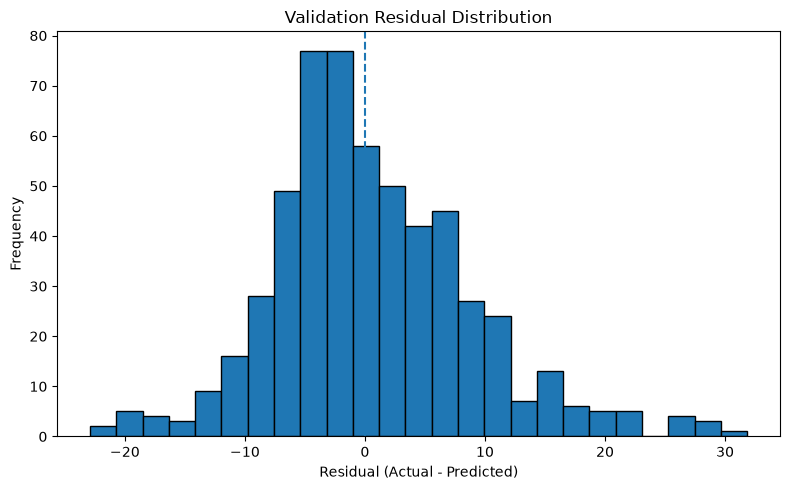

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(uncertainty_df["Residual"],bins=25,edgecolor="black")

plt.axvline(0,linestyle="--")

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Validation Residual Distribution")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/modeling/"
    "gb_validation_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.4 Empirical Prediction Interval

A 90% empirical prediction interval is constructed using the 5th and 95th
percentiles of validation residuals.

This approach does not assume normally distributed errors and directly reflects
the forecasting error observed on unseen validation data.

In [36]:
# ---------------------------------------------------------
# 90% Empirical Residual Bounds
# ---------------------------------------------------------

lower_residual_bound = (uncertainty_df["Residual"].quantile(0.05))

upper_residual_bound = (uncertainty_df["Residual"].quantile(0.95))

print("5th Percentile Residual:",round(lower_residual_bound, 2))

print("95th Percentile Residual:",round(upper_residual_bound, 2))

5th Percentile Residual: -11.21
95th Percentile Residual: 15.71


In [37]:
def demand_prediction_interval(
    predicted_demand,
    lower_residual,
    upper_residual
):
    
    lower_demand = (predicted_demand + lower_residual)

    upper_demand = (predicted_demand + upper_residual)

    return (
        max(lower_demand, 0),
        max(upper_demand, 0)
    )

In [38]:
example_lower, example_upper = (
    demand_prediction_interval(
        predicted_demand=70,
        lower_residual=lower_residual_bound,
        upper_residual=upper_residual_bound
    )
)

print(
    "Prediction Interval:",
    round(example_lower, 2),
    "to",
    round(example_upper, 2)
)

Prediction Interval: 58.79 to 85.71


In [40]:
uncertainty_df["Lower_Bound"] = (uncertainty_df["Predicted_Demand"]+ lower_residual_bound)

uncertainty_df["Upper_Bound"] = (uncertainty_df["Predicted_Demand"]+ upper_residual_bound)

uncertainty_df["Lower_Bound"] = (uncertainty_df["Lower_Bound"].clip(lower=0))

uncertainty_df["Upper_Bound"] = (uncertainty_df["Upper_Bound"].clip(lower=0))

uncertainty_df["Inside_Interval"] = (
    (uncertainty_df["Future_Latent_Demand"]>= uncertainty_df["Lower_Bound"])
    &
    (uncertainty_df["Future_Latent_Demand"]<= uncertainty_df["Upper_Bound"])
)

coverage = (uncertainty_df["Inside_Interval"].mean()* 100)

print("Empirical Coverage:",round(coverage, 2),"%")

Empirical Coverage: 90.0 %


### 6.5 Prediction Uncertainty Result

The selected Gradient Boosting model shows residuals that are reasonably centered
around zero, with only a small overall prediction bias.

The 5th and 95th percentile residuals are:

- Lower residual bound: -11.21 units
- Upper residual bound: +15.71 units

These values define a 90% empirical prediction interval.

For example, a point forecast of 70 units produces an estimated demand range of
approximately 58.79 to 85.71 units.

The interval is asymmetric because historical underprediction errors have a
larger upper tail than overprediction errors.

The 90% coverage obtained on the calibration dataset is expected because the
interval bounds were derived from the same validation residuals.

In [41]:
test_uncertainty_df = pd.read_csv(
    "../data/processed/"
    "smartmarkdown_test_predictions.csv",
    parse_dates=["Week_Start"]
)

display(test_uncertainty_df.head())

,Week_Start,SKU_ID,Category,Future_Latent_Demand,Predicted_Demand
0,2025-09-15,SKU001,Apparel,82.0,82.443968
1,2025-09-22,SKU001,Apparel,70.0,60.983032
2,2025-09-29,SKU001,Apparel,93.0,89.912790
3,2025-10-06,SKU001,Apparel,77.0,64.933382
4,2025-10-13,SKU001,Apparel,61.0,56.422657


In [42]:
test_uncertainty_df["Lower_Bound"] = (test_uncertainty_df["Predicted_Demand"]+ lower_residual_bound).clip(lower=0)

test_uncertainty_df["Upper_Bound"] = (test_uncertainty_df["Predicted_Demand"]+ upper_residual_bound).clip(lower=0)

test_uncertainty_df["Inside_Interval"] = (
    (
        test_uncertainty_df["Future_Latent_Demand"]
        >= test_uncertainty_df["Lower_Bound"]
    )
    &
    (
        test_uncertainty_df["Future_Latent_Demand"]
        <= test_uncertainty_df["Upper_Bound"]
    )
)

test_coverage = (test_uncertainty_df["Inside_Interval"].mean()* 100)

print("Test Interval Coverage:",round(test_coverage, 2),"%")

Test Interval Coverage: 85.5 %


### 6.5 Test-Set Prediction Interval Validation

The 90% empirical prediction interval was calibrated using validation residuals
and then evaluated on the untouched test period.

The resulting test-set coverage was:

- Target coverage: 90%
- Observed test coverage: 85.5%

The interval therefore generalizes reasonably well, but slightly under-covers
future demand.

This suggests that forecast uncertainty is not perfectly constant across all
products and demand levels. Further analysis is performed to determine whether
high-demand or specific SKU segments require wider uncertainty ranges.

In [43]:
# ---------------------------------------------------------
# Test Interval Coverage by Demand Level
# ---------------------------------------------------------

test_uncertainty_df["Demand_Band"] = pd.cut(
    test_uncertainty_df["Future_Latent_Demand"],
    bins=[0, 25, 50, 75, np.inf],
    labels=[
        "Low (<=25)",
        "Medium (26-50)",
        "High (51-75)",
        "Very High (>75)"
    ]
)

coverage_by_demand = (
    test_uncertainty_df
    .groupby("Demand_Band", observed=True)
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Avg_Demand=("Future_Latent_Demand", "mean"),
        Coverage_Pct=("Inside_Interval", lambda x: x.mean() * 100)
    )
    .round(2)
)

display(coverage_by_demand)

,Observations,Avg_Demand,Coverage_Pct
Demand_Band,,,
Low (<=25),107,19.74,90.65
Medium (26-50),357,36.85,91.88
High (51-75),99,60.87,72.73
Very High (>75),37,89.92,43.24


In [46]:
test_uncertainty_df = test_uncertainty_df.merge(
    cluster_mapping[
        [
            "SKU_ID",
            "Cluster_Label"
        ]
    ],
    on="SKU_ID",
    how="left"
)

In [47]:
coverage_by_cluster = (
    test_uncertainty_df
    .groupby("Cluster_Label")
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Avg_Demand=("Future_Latent_Demand", "mean"),
        Coverage_Pct=("Inside_Interval", lambda x: x.mean() * 100)
    )
    .round(2)
)

display(coverage_by_cluster)

,Observations,Avg_Demand,Coverage_Pct
Cluster_Label,,,
High-Demand Fast-Moving,270,47.26,83.33
Slow-Moving Markdown-Responsive,210,33.12,93.33
Volatile Low-Response,120,40.86,76.67


### 6.6 Cluster-Specific Prediction Intervals

The global prediction interval performs well for normal-demand observations but
under-covers high-demand and volatile SKU behaviour.

Because SKU cluster membership is known before forecasting, separate residual
bounds are estimated for each behavioural cluster.

This allows more volatile SKU segments to receive wider uncertainty intervals
without unnecessarily widening intervals for more stable products.

In [48]:
# ---------------------------------------------------------
# Add Cluster Information to Validation Residuals
# ---------------------------------------------------------

uncertainty_df = uncertainty_df.merge(
    cluster_mapping[
        [
            "SKU_ID",
            "Cluster_Label"
        ]
    ],
    on="SKU_ID",
    how="left"
)

display(
    uncertainty_df[
        [
            "SKU_ID",
            "Cluster_Label",
            "Residual"
        ]
    ].head()
)

,SKU_ID,Cluster_Label,Residual
0,SKU001,High-Demand Fast-Moving,3.110356
1,SKU001,High-Demand Fast-Moving,-22.899973
2,SKU001,High-Demand Fast-Moving,-16.524341
3,SKU001,High-Demand Fast-Moving,8.354173
4,SKU001,High-Demand Fast-Moving,-6.932429


In [49]:
# ---------------------------------------------------------
# Cluster-Specific 90% Residual Bounds
# ---------------------------------------------------------

cluster_interval_bounds = (
    uncertainty_df
    .groupby("Cluster_Label")["Residual"]
    .quantile([0.05, 0.95])
    .unstack()
    .rename(
        columns={
            0.05: "Lower_Residual",
            0.95: "Upper_Residual"
        }
    )
    .round(2)
)

display(cluster_interval_bounds)

,Lower_Residual,Upper_Residual
Cluster_Label,,
High-Demand Fast-Moving,-13.74,18.86
Slow-Moving Markdown-Responsive,-7.48,10.67
Volatile Low-Response,-9.36,11.59


In [50]:
test_cluster_interval_df = (
    test_uncertainty_df
    .merge(
        cluster_interval_bounds,
        on="Cluster_Label",
        how="left"
    )
)

In [51]:
test_cluster_interval_df["Cluster_Lower_Bound"] = (
    test_cluster_interval_df["Predicted_Demand"]
    + test_cluster_interval_df["Lower_Residual"]
).clip(lower=0)

test_cluster_interval_df["Cluster_Upper_Bound"] = (
    test_cluster_interval_df["Predicted_Demand"]
    + test_cluster_interval_df["Upper_Residual"]
).clip(lower=0)

test_cluster_interval_df["Inside_Cluster_Interval"] = (
    (
        test_cluster_interval_df["Future_Latent_Demand"]
        >= test_cluster_interval_df["Cluster_Lower_Bound"]
    )
    &
    (
        test_cluster_interval_df["Future_Latent_Demand"]
        <= test_cluster_interval_df["Cluster_Upper_Bound"]
    )
)

In [52]:
cluster_interval_coverage = (
    test_cluster_interval_df["Inside_Cluster_Interval"].mean()* 100
)

print("Cluster-Specific Test Coverage:",round(cluster_interval_coverage, 2),"%")

Cluster-Specific Test Coverage: 82.5 %


In [53]:
cluster_interval_performance = (
    test_cluster_interval_df
    .groupby("Cluster_Label")
    .agg(
        Observations=("Future_Latent_Demand", "size"),

        Coverage_Pct=("Inside_Cluster_Interval",lambda x: x.mean() * 100),

        Avg_Interval_Width=("Cluster_Upper_Bound",lambda x: 0)
    )
)

In [54]:
test_cluster_interval_df["Interval_Width"] = (
    test_cluster_interval_df["Cluster_Upper_Bound"]
    - test_cluster_interval_df["Cluster_Lower_Bound"]
)

cluster_interval_performance = (
    test_cluster_interval_df
    .groupby("Cluster_Label")
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Coverage_Pct=(
            "Inside_Cluster_Interval",
            lambda x: x.mean() * 100
        ),
        Avg_Interval_Width=(
            "Interval_Width",
            "mean"
        )
    )
    .round(2)
)

display(cluster_interval_performance)

,Observations,Coverage_Pct,Avg_Interval_Width
Cluster_Label,,,
High-Demand Fast-Moving,270,89.26,32.60
Slow-Moving Markdown-Responsive,210,80.95,18.15
Volatile Low-Response,120,70.00,20.95


### 6.7 Cluster-Specific Interval Evaluation

Cluster-specific residual intervals were tested to determine whether behavioural
segmentation could improve uncertainty calibration.

However, overall test coverage decreased from 85.5% with the global interval
to 82.5% with cluster-specific intervals.

Although coverage improved for the High-Demand Fast-Moving cluster, coverage
decreased substantially for the other clusters, particularly the Volatile
Low-Response segment.

Therefore, cluster-specific residual intervals are not adopted for the final
uncertainty framework.

In [55]:
# ---------------------------------------------------------
# Predicted-Demand Bands on Validation Data
# ---------------------------------------------------------

uncertainty_df["Predicted_Demand_Band"] = pd.cut(
    uncertainty_df["Predicted_Demand"],
    bins=[0, 25, 50, 75, np.inf],
    labels=[
        "Low (<=25)",
        "Medium (26-50)",
        "High (51-75)",
        "Very High (>75)"
    ]
)

predicted_band_residuals = (
    uncertainty_df
    .groupby("Predicted_Demand_Band", observed=True)
    .agg(
        Observations=("Residual", "size"),
        Avg_Predicted_Demand=("Predicted_Demand", "mean"),
        Residual_Std=("Residual", "std"),
        Median_Absolute_Error=("Absolute_Error", "median")
    )
    .round(2)
)

display(predicted_band_residuals)

,Observations,Avg_Predicted_Demand,Residual_Std,Median_Absolute_Error
Predicted_Demand_Band,,,,
Low (<=25),104,19.70,4.55,2.83
Medium (26-50),359,35.57,8.02,5.44
High (51-75),93,58.28,12.00,7.56
Very High (>75),4,77.03,7.66,5.68


In [57]:
predicted_band_bounds = (
    uncertainty_df
    .groupby("Predicted_Demand_Band", observed=True)["Residual"]
    .quantile([0.05, 0.95])
    .unstack()
    .rename(
        columns={
            0.05: "Lower_Residual",
            0.95: "Upper_Residual"
        }
    )
    .round(2)
)

display(predicted_band_bounds)

,Lower_Residual,Upper_Residual
Predicted_Demand_Band,,
Low (<=25),-4.81,7.51
Medium (26-50),-11.21,15.07
High (51-75),-16.98,25.71
Very High (>75),-3.50,12.69


### 6.8 Predicted-Demand-Based Uncertainty

Forecast error increases as predicted demand increases.

The original very-high-demand band contained too few validation observations
to estimate reliable residual percentiles.

Therefore, predicted demand is grouped into three practical uncertainty bands:

- Low: <= 25 units
- Medium: 26–50 units
- High: > 50 units

These bands are based only on predicted demand, which is available at forecast
time and can therefore be used in production.

In [58]:
# ---------------------------------------------------------
# Three Predicted-Demand Uncertainty Bands
# ---------------------------------------------------------

uncertainty_df["Predicted_Demand_Band_3"] = pd.cut(
    uncertainty_df["Predicted_Demand"],
    bins=[0, 25, 50, np.inf],
    labels=[
        "Low (<=25)",
        "Medium (26-50)",
        "High (>50)"
    ]
)

In [60]:
band_3_summary = (
    uncertainty_df
    .groupby("Predicted_Demand_Band_3", observed=True)
    .agg(
        Observations=("Residual", "size"),
        Avg_Predicted_Demand=("Predicted_Demand", "mean"),
        Residual_Std=("Residual", "std"),
        Median_Absolute_Error=("Absolute_Error", "median")
    )
    .round(2)
)

display(band_3_summary)

,Observations,Avg_Predicted_Demand,Residual_Std,Median_Absolute_Error
Predicted_Demand_Band_3,,,,
Low (<=25),104,19.70,4.55,2.83
Medium (26-50),359,35.57,8.02,5.44
High (>50),97,59.05,11.86,7.27


In [61]:
predicted_band_bounds_3 = (
    uncertainty_df
    .groupby(
        "Predicted_Demand_Band_3",
        observed=True
    )["Residual"]
    .quantile([0.05, 0.95])
    .unstack()
    .rename(
        columns={
            0.05: "Lower_Residual",
            0.95: "Upper_Residual"
        }
    )
    .round(2)
)

display(predicted_band_bounds_3)

,Lower_Residual,Upper_Residual
Predicted_Demand_Band_3,,
Low (<=25),-4.81,7.51
Medium (26-50),-11.21,15.07
High (>50),-16.75,25.51


In [62]:
test_uncertainty_df["Predicted_Demand_Band_3"] = pd.cut(
    test_uncertainty_df["Predicted_Demand"],
    bins=[0, 25, 50, np.inf],
    labels=[
        "Low (<=25)",
        "Medium (26-50)",
        "High (>50)"
    ]
)

In [63]:
test_adaptive_interval_df = (
    test_uncertainty_df
    .merge(
        predicted_band_bounds_3,
        left_on="Predicted_Demand_Band_3",
        right_index=True,
        how="left"
    )
)

In [64]:
test_adaptive_interval_df["Adaptive_Lower_Bound"] = (
    test_adaptive_interval_df["Predicted_Demand"]
    + test_adaptive_interval_df["Lower_Residual"]
).clip(lower=0)

test_adaptive_interval_df["Adaptive_Upper_Bound"] = (
    test_adaptive_interval_df["Predicted_Demand"]
    + test_adaptive_interval_df["Upper_Residual"]
).clip(lower=0)

In [65]:
test_adaptive_interval_df["Inside_Adaptive_Interval"] = (
    (
        test_adaptive_interval_df["Future_Latent_Demand"] >= test_adaptive_interval_df["Adaptive_Lower_Bound"]
    )
    &
    (
        test_adaptive_interval_df["Future_Latent_Demand"] <= test_adaptive_interval_df["Adaptive_Upper_Bound"]
    )
)

In [66]:
adaptive_coverage = (test_adaptive_interval_df["Inside_Adaptive_Interval"].mean()* 100)

print("Adaptive Test Coverage:",round(adaptive_coverage, 2),"%")

Adaptive Test Coverage: 87.33 %


In [67]:
test_adaptive_interval_df["Adaptive_Interval_Width"] = (
    test_adaptive_interval_df["Adaptive_Upper_Bound"]
    - test_adaptive_interval_df["Adaptive_Lower_Bound"]
)

In [69]:
adaptive_interval_performance = (
    test_adaptive_interval_df
    .groupby("Predicted_Demand_Band_3",observed=True)
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Coverage_Pct=("Inside_Adaptive_Interval",lambda x: x.mean() * 100),
        Avg_Interval_Width=("Adaptive_Interval_Width","mean")
    )
    .round(2)
)

display(adaptive_interval_performance)

,Observations,Coverage_Pct,Avg_Interval_Width
Predicted_Demand_Band_3,,,
Low (<=25),77,79.22,12.32
Medium (26-50),386,88.86,26.28
High (>50),137,87.59,42.26


### 6.9 Adaptive Prediction Interval Evaluation

Prediction uncertainty was adjusted according to the model's predicted demand level.

Three forecast bands were used:

- Low Demand: <= 25 units
- Medium Demand: 26–50 units
- High Demand: > 50 units

Forecast-error variability increased substantially with predicted demand, supporting
the use of wider intervals for higher-demand forecasts.

The adaptive interval achieved 87.33% coverage on the untouched test set,
improving over:

- Global interval coverage: 85.50%
- Cluster-specific interval coverage: 82.50%

The adaptive approach also produces progressively wider intervals as forecast demand
increases, making it better aligned with observed forecasting risk.

Therefore, predicted-demand-based adaptive intervals are selected for the
SmartMarkdown uncertainty framework.

In [70]:
# ---------------------------------------------------------
# 95% Adaptive Prediction Interval
# ---------------------------------------------------------

predicted_band_bounds_95 = (
    uncertainty_df
    .groupby(
        "Predicted_Demand_Band_3",
        observed=True
    )["Residual"]
    .quantile([0.025, 0.975])
    .unstack()
    .rename(columns={0.025: "Lower_Residual_95",0.975: "Upper_Residual_95"})
    .round(2)
)

display(predicted_band_bounds_95)

,Lower_Residual_95,Upper_Residual_95
Predicted_Demand_Band_3,,
Low (<=25),-5.53,9.25
Medium (26-50),-12.56,17.99
High (>50),-19.91,27.43


In [71]:
test_adaptive_95_df = (
    test_uncertainty_df
    .merge(
        predicted_band_bounds_95,
        left_on="Predicted_Demand_Band_3",
        right_index=True,
        how="left"
    )
)

test_adaptive_95_df["Lower_Bound_95"] = (
    test_adaptive_95_df["Predicted_Demand"]
    + test_adaptive_95_df["Lower_Residual_95"]
).clip(lower=0)

test_adaptive_95_df["Upper_Bound_95"] = (
    test_adaptive_95_df["Predicted_Demand"]
    + test_adaptive_95_df["Upper_Residual_95"]
).clip(lower=0)

test_adaptive_95_df["Inside_95_Interval"] = (
    (
        test_adaptive_95_df["Future_Latent_Demand"]
        >= test_adaptive_95_df["Lower_Bound_95"]
    )
    &
    (
        test_adaptive_95_df["Future_Latent_Demand"]
        <= test_adaptive_95_df["Upper_Bound_95"]
    )
)

coverage_95 = (test_adaptive_95_df["Inside_95_Interval"].mean()* 100)

print("95% Adaptive Test Coverage:",round(coverage_95, 2),"%")

95% Adaptive Test Coverage: 93.17 %


In [72]:
test_adaptive_95_df["Interval_Width_95"] = (
    test_adaptive_95_df["Upper_Bound_95"]
    - test_adaptive_95_df["Lower_Bound_95"]
)

adaptive_95_performance = (
    test_adaptive_95_df
    .groupby("Predicted_Demand_Band_3",observed=True)
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Coverage_Pct=("Inside_95_Interval",lambda x: x.mean() * 100),
        Avg_Interval_Width=("Interval_Width_95", "mean")).round(2)
)

display(adaptive_95_performance)

,Observations,Coverage_Pct,Avg_Interval_Width
Predicted_Demand_Band_3,,,
Low (<=25),77,89.61,14.78
Medium (26-50),386,94.56,30.55
High (>50),137,91.24,47.34


## Final Prediction Uncertainty Framework

A 95% adaptive prediction interval was evaluated using predicted-demand bands.

The final bands are:

- Low Demand: <= 25 units
- Medium Demand: 26–50 units
- High Demand: > 50 units

The corresponding residual bounds are:

- Low: -5.53 to +9.25
- Medium: -12.56 to +17.99
- High: -19.91 to +27.43

The adaptive 95% interval achieved 93.17% coverage on the untouched test set.

Coverage remained reasonably consistent across demand bands:

- Low Demand: 89.61%
- Medium Demand: 94.56%
- High Demand: 91.24%

Although the intervals are wider than the 90% version, they provide better
out-of-sample calibration and are more appropriate for downstream markdown
decisions where underestimating demand uncertainty could affect profitability
and inventory decisions.

Therefore, the 95% predicted-demand-based adaptive interval is selected as the
final uncertainty framework.

------------

In [74]:
def get_adaptive_prediction_interval(predicted_demand):
    
    if predicted_demand <= 25:
        lower_residual = -5.53
        upper_residual = 9.25

    elif predicted_demand <= 50:
        lower_residual = -12.56
        upper_residual = 17.99

    else:
        lower_residual = -19.91
        upper_residual = 27.43

    lower_bound = max(
        predicted_demand + lower_residual,
        0
    )

    upper_bound = max(
        predicted_demand + upper_residual,
        0
    )

    return lower_bound, upper_bound

In [75]:
for demand in [20, 40, 70]:

    lower, upper = get_adaptive_prediction_interval(demand)

    print(
        f"Predicted Demand: {demand}",
        f"| Interval: {round(lower,2)} to {round(upper,2)}"
    )

Predicted Demand: 20 | Interval: 14.47 to 29.25
Predicted Demand: 40 | Interval: 27.44 to 57.99
Predicted Demand: 70 | Interval: 50.09 to 97.43


In [77]:
price_response_df.to_csv(
    "../data/processed/"
    "smartmarkdown_price_response.csv",
    index=False
)

print("Price-response table saved successfully.")

Price-response table saved successfully.
